# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

### ФИО: Московкин Александр Николаевич
### ИСУ: 472264
### Группа: J3312

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- Устройство: Google Colab, GPU Tesla T4 (torch 2.14.1, transformers 5.22.1, datasets 5.1.0), финальный прогон с `FAST_MODE = False`
- Модель: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT
- Датасет: Collection3, [RCC-MSU/collection3](https://huggingface.co/datasets/RCC-MSU/collection3), ветка `refs/convert/parquet` (sha `18841ce4c41a94aaed0041342c6a7cb0c59cfcfe`), лицензия в карточке указана как `other`
- Бонусы: 6.2 (сравнение с [DeepPavlov/rubert-base-cased](https://huggingface.co/DeepPavlov/rubert-base-cased), revision `4036cab694767a299f2b9e6492909664d9414229`, лицензия в карточке не указана), 6.3, 6.4, 6.5. Бонус 6.1 не делал
- Источники: документация Hugging Face (Token classification guide, `Trainer`, `TrainingArguments`), документация seqeval, документация `torch.onnx`, ONNX Runtime и dynamic quantization в PyTorch, материалы курса
- Нерешенных задач в основной части нет

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False  # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 6
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}
print(REVISION)

e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae


In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Collection3 - русские новости, поэтому нужен энкодер, который хорошо знает русский. rubert-tiny2 - маленький BERT (29.1M параметров, 3 слоя, hidden 312, словарь 83 828 сабвордов), дистиллированный из больших моделей на русских и англо-русских текстах, лицензия MIT. Он быстрый: прямой проход батча 32 x 64 занимает 6.8 мс на T4, полное обучение на 9.3 тыс. предложений за 6 эпох - около минуты, поэтому можно спокойно делать абляцию и бонусы. Токенизатор режет русские слова экономно (1.14 сабворда на слово на validation), а за малый размер мы платим качеством: по бенчмаркам автора на NER он уступает base-моделям.

Альтернативы: `DeepPavlov/rubert-base-cased` (~178M параметров, в 6 раз больше, обучен на русской Википедии и новостях) по карточке и бенчмаркам заметно сильнее на NER, но в 3-4 раза дольше обучается (в 6.2 вышло 234 с против 64 с). `FacebookAI/xlm-roberta-base` (~280M) многоязычный, со словарем 250k, он еще тяжелее и большую часть емкости тратит на другие языки.

Без фиксации `revision` `main` может начать указывать на другой коммит: например, по выводу выше репозиторий обновлялся 30.12.2025. Если владелец перезальет веса, токенизатор или конфиг, поменяются разбиение на сабворды, число параметров и все метрики, тесты на `params_by_block` могут упасть, а результаты перестанут воспроизводиться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    base = getattr(model, model.base_model_prefix, model)
    container = next((getattr(base, n) for n in ('encoder', 'transformer') if hasattr(base, n)), base)
    layer_list = next(getattr(container, n) for n in ('layer', 'layers') if hasattr(container, n))
    seen = set()

    def count(module):
        n = 0
        for p in module.parameters():
            if id(p) not in seen:
                seen.add(id(p))
                n += p.numel()
        return n

    head = count(model.classifier)
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in layer_list]
    total = sum(p.numel() for p in model.parameters())
    return {'embeddings': embeddings, 'encoder': sum(layers), 'head': head,
            'other': total - embeddings - sum(layers) - head, 'layers': layers}

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

for i, words in enumerate(demo_texts):
    print(f'{len(words)} слов -> {sum(enc["attention_mask"][i].tolist())} сабвордов:', enc.tokens(i))
    print('   word_ids:', enc.word_ids(i))
print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape), '(выход эмбеддингов)' if i == 0 else f'(выход слоя {i})')
print('logits        ', tuple(out.logits.shape))

6 слов -> 11 сабвордов: ['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
   word_ids: [None, 0, 1, 1, 2, 3, 4, 4, 4, 5, None]
6 слов -> 10 сабвордов: ['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']
   word_ids: [None, 0, 0, 0, 1, 2, 3, 4, 5, None, None]
input_ids      (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312) (выход эмбеддингов)
hidden_states[1] (2, 11, 312) (выход слоя 1)
hidden_states[2] (2, 11, 312) (выход слоя 2)
hidden_states[3] (2, 11, 312) (выход слоя 3)
logits         (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.8 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Вход: `input_ids` и `attention_mask` формы (2, 11), батч из 2 предложений, дополненных до 11 сабвордов. Эмбеддинги (таблица слов 83 828 x 312, позиционные 2048 x 312, type 2 x 312, LayerNorm) дают `hidden_states[0]` формы (2, 11, 312). Дальше 3 слоя энкодера, каждый (2, 11, 312) -> (2, 11, 312) и по 767 184 параметра, это `hidden_states[1..3]`. Голова (dropout + `Linear(312, 7)`, 2 191 параметр) дает `logits` формы (2, 11, 7).

Больше всего параметров в эмбеддингах: 26.8M из 29.1M (92.1%), почти все в таблице слов (83 828 x 312 = 26.2M). У модели большой словарь и маленький hidden, поэтому сами слои энкодера занимают всего 2.3M (7.9%).

Токены обмениваются информацией только в слоях энкодера (через attention). Эмбеддинги и голова обрабатывают каждый токен независимо: позиционный эмбеддинг лишь добавляет номер позиции, а LayerNorm и Linear применяются к каждому вектору отдельно.

`T` больше числа слов, потому что добавляются `[CLS]` и `[SEP]`, часть слов режется на несколько сабвордов («Воткинске» -> `Вот`, `##кинс`, `##ке`, «ITMO» -> 3 сабворда), а короткое предложение в батче дополняется `[PAD]` до длины самого длинного (у второго предложения 10 значимых сабвордов и один `[PAD]`).

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
DATASET_REVISION = 'refs/convert/parquet'
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
if 'validation' not in raw:
    parts = raw['train'].train_test_split(test_size=0.15, seed=SEED)
    raw = DatasetDict(train=parts['train'], validation=parts['test'], test=raw['test'])
tag_feature = raw['train'].features['ner_tags'].feature
LABEL_NAMES = list(tag_feature.names) if hasattr(tag_feature, 'names') else ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
ds_info = HfApi().dataset_info(DATASET_ID)
ds_card = ds_info.card_data.to_dict() if ds_info.card_data else {}
print(raw)
print('LABEL_NAMES', LABEL_NAMES)
print(f'dataset sha: {ds_info.sha}, license: {ds_card.get("license")}, language: {ds_card.get("language")}')
for ex in raw['train'].select(range(2)):
    print(list(zip(ex['tokens'], [LABEL_NAMES[t] for t in ex['ner_tags']])))

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
LABEL_NAMES ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
dataset sha: 18841ce4c41a94aaed0041342c6a7cb0c59cfcfe, license: ['other'], language: ['ru']
[('Дополнение', 'O'), (':', 'O'), ('Д', 'B-PER'), ('.', 'I-PER'), ('Медведев', 'I-PER'), ('присвоил', 'O'), ('звания', 'O'), ('сотрудников', 'O'), ('полиции', 'O'), ('и', 'O'), ('переназначил', 'O'), ('14', 'O'), ('руководителей', 'O'), ('УВД', 'B-ORG'), (',', 'O'), ('ГУВД', 'B-ORG'), ('и', 'O'), ('МВД', 'B-ORG'), ('по', 'O'), ('субъектам', 'O'), ('РФ', 'B-LOC'), ('.', 'O')]
[('Президент', 'O'), ('России', 'B-LOC'), ('Дмитрий', 'B-PER'), ('Медведев', 'I-PER'), ('присвоил', 'O'), ('звания', 'O'), ('сотрудников', '

train       предложений   9301, с сущностями 80.5%, сущностей  18247, предложений с I- без B- 5
validation  предложений   2153, с сущностями 76.6%, сущностей   4117, предложений с I- без B- 0
test        предложений   1922, с сущностями 81.7%, сущностей   4001, предложений с I- без B- 1

тип          train  validation        test  доля train
LOC           4881        1168        1175       26.7%
ORG           5960        1308        1256       32.7%
PER           7406        1641        1570       40.6%

длина спана в словах (5 = 5+), train: {1: 9025, 2: 6124, 3: 2068, 4: 373, 5: 657}
  LOC: средняя 1.32, max 8, однословных 77.6%
  ORG: средняя 2.00, max 18, однословных 53.8%
  PER: средняя 2.01, max 10, однословных 27.4%
длина предложения train       mean 20.2, median 18, p95 41, max 256
длина предложения validation  mean 20.4, median 18, p95 41, max 118
длина предложения test        mean 20.9, median 19, p95 42, max 122
train: сабвордов на предложение mean 25.1, длиннее MAX_LENGTH=12

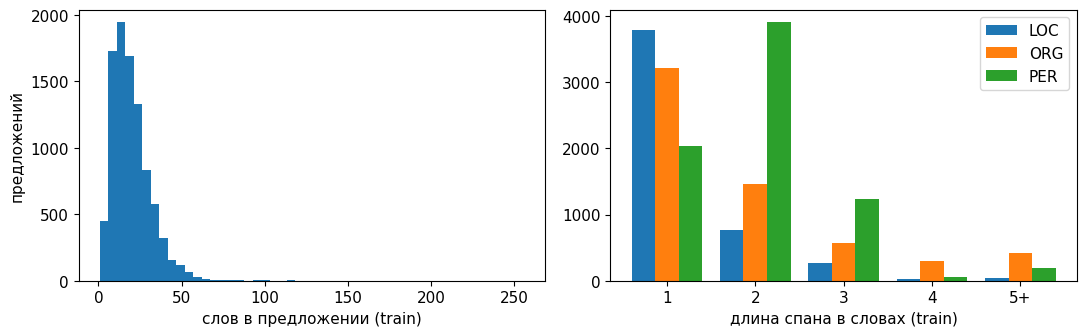

In [14]:
def quick_spans(tags):
    spans, start, cur = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        typ = None if tag == 'O' else tag[2:]
        if cur is not None and (typ != cur or tag.startswith('B-')):
            spans.append((start, i, cur))
            cur = None
        if typ is not None and cur is None:
            start, cur = i, typ
    return spans


types_all = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
stats_rows, span_lens, sent_lens = {}, {}, {}
for split in ['train', 'validation', 'test']:
    counter, lens, n_with, n_bad_i = collections.Counter(), collections.Counter(), 0, 0
    for tags in raw[split]['ner_tags']:
        names = [LABEL_NAMES[t] for t in tags]
        spans = quick_spans(names)
        n_with += bool(spans)
        n_bad_i += any(n.startswith('I-') and (i == 0 or names[i - 1][2:] != n[2:]) for i, n in enumerate(names))
        for s, e, t in spans:
            counter[t] += 1
            lens[min(e - s, 5)] += 1
    stats_rows[split] = counter
    span_lens[split] = lens
    sent_lens[split] = np.array([len(ws) for ws in raw[split]['tokens']])
    print(f'{split:<11} предложений {len(raw[split]):>6}, с сущностями {n_with / len(raw[split]):.1%}, '
          f'сущностей {sum(counter.values()):>6}, предложений с I- без B- {n_bad_i}')

print(f'\n{"тип":<6}' + ''.join(f'{s:>12}' for s in stats_rows) + f'{"доля train":>12}')
for t in types_all:
    print(f'{t:<6}' + ''.join(f'{stats_rows[s][t]:>12}' for s in stats_rows) + f'{stats_rows["train"][t] / sum(stats_rows["train"].values()):>12.1%}')

print('\nдлина спана в словах (5 = 5+), train:', dict(sorted(span_lens['train'].items())))
for t in types_all:
    lens_t = [e - s for tags in raw['train']['ner_tags'] for s, e, tt in quick_spans([LABEL_NAMES[x] for x in tags]) if tt == t]
    print(f'  {t}: средняя {np.mean(lens_t):.2f}, max {max(lens_t)}, однословных {np.mean(np.array(lens_t) == 1):.1%}')
for split, arr in sent_lens.items():
    print(f'длина предложения {split:<11} mean {arr.mean():.1f}, median {np.median(arr):.0f}, p95 {np.percentile(arr, 95):.0f}, max {arr.max()}')

n_sub = np.array([len(tokenizer(ws, is_split_into_words=True)['input_ids']) for ws in raw['train']['tokens']])
print(f'train: сабвордов на предложение mean {n_sub.mean():.1f}, длиннее MAX_LENGTH={MAX_LENGTH}: {(n_sub > MAX_LENGTH).sum()}')

train_surface = collections.Counter()
for ws, tags in zip(raw['train']['tokens'], raw['train']['ner_tags']):
    for s, e, t in quick_spans([LABEL_NAMES[x] for x in tags]):
        train_surface[(' '.join(ws[s:e]), t)] += 1
val_ents = [(' '.join(ws[s:e]), t) for ws, tags in zip(raw['validation']['tokens'], raw['validation']['ner_tags'])
            for s, e, t in quick_spans([LABEL_NAMES[x] for x in tags])]
print(f'сущности validation, которые с тем же типом встречались в train: {np.mean([v in train_surface for v in val_ents]):.1%}')
print('самые частые сущности train:', train_surface.most_common(8))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(sent_lens['train'], bins=50)
axes[0].set_xlabel('слов в предложении (train)')
axes[0].set_ylabel('предложений')
width = 0.8 / len(types_all)
for j, t in enumerate(types_all):
    lens_t = collections.Counter(min(e - s, 5) for tags in raw['train']['ner_tags']
                                 for s, e, tt in quick_spans([LABEL_NAMES[x] for x in tags]) if tt == t)
    axes[1].bar(np.arange(1, 6) + j * width, [lens_t[k] for k in range(1, 6)], width=width, label=t)
axes[1].set_xticks(np.arange(1, 6) + width, ['1', '2', '3', '4', '5+'])
axes[1].set_xlabel('длина спана в словах (train)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 - корпус русских новостных текстов, расширение коллекции Persons-1000 (Можарова, Лукашевич, 2016): к разметке персон добавили организации и локации. Разметка ручная. В карточке на HF лицензия указана как `other`, корпус открыт для исследовательского использования. Типы: PER, ORG, LOC. В train 9 301 предложение и 18 247 сущностей (PER 7 406, ORG 5 960, LOC 4 881), в validation 2 153 и 4 117 (1 641 / 1 308 / 1 168), в test 1 922 и 4 001 (1 570 / 1 256 / 1 175). Совсем редких типов нет, самый малочисленный LOC (26.7% сущностей train), так что классы сбалансированы.

Особенности: средняя длина спана у PER и ORG около 2 слов, у LOC 1.32. Однословных среди PER всего 27.4%, а ORG бывают очень длинными (до 18 слов, 657 спанов train длиной 5+), так что границы ORG должны быть самым трудным местом. Предложения в среднем по 20 слов (p95 = 41, max 256), длиннее 128 сабвордов только 10 предложений train. Шум разметки есть, но небольшой: 5 предложений train и 1 test содержат `I-` без `B-`, кавычки в названиях организаций то входят в спан, то нет. Только 60.4% сущностей validation встречались в train с тем же типом, поэтому модели нужно обобщать, запоминания мало.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, cur = [], None, None
    for i, tag in enumerate(tags):
        if tag == 'O':
            if cur is not None:
                spans.append((start, i, cur))
                cur = None
            continue
        prefix, typ = tag[0], tag[2:]
        if prefix == 'B' or typ != cur:
            if cur is not None:
                spans.append((start, i, cur))
            start, cur = i, typ
    if cur is not None:
        spans.append((start, len(tags), cur))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is not None:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        else:
            labels.append(-100)
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
conversion = {}
for split in raw:
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for i, ex in enumerate(raw[split]):
            tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
            assert len(tags) == len(ex['tokens'])
            rec = {'id': i, 'tokens': ex['tokens'], 'spans': [[s, e, t] for s, e, t in bio_to_spans(tags)]}
            f.write(json.dumps(rec, ensure_ascii=False) + '\n')

    n_exact, n_spans_only, n_spans, bad_examples = 0, 0, 0, []
    with path.open(encoding='utf-8') as f:
        records = [json.loads(line) for line in f]
    assert len(records) == len(raw[split])
    for rec, ex in zip(records, raw[split]):
        orig = [LABEL_NAMES[t] for t in ex['ner_tags']]
        spans = [tuple(s) for s in rec['spans']]
        back = spans_to_bio(spans, len(rec['tokens']))
        assert rec['tokens'] == list(ex['tokens'])
        assert bio_to_spans(back) == bio_to_spans(orig) == spans
        assert all(a[1] <= b[0] for a, b in zip(spans, spans[1:]))
        n_spans += len(spans)
        if back == orig:
            n_exact += 1
        else:
            n_spans_only += 1
            bad_examples.append([(w, o) for w, o, b in zip(rec['tokens'], orig, back) if o != b][:4])
    n_empty = sum(1 for ws in raw[split]['tokens'] for w in ws if not w.strip())
    conversion[split] = dict(sentences=len(records), spans=n_spans, exact=n_exact, spans_only=n_spans_only, empty_words=n_empty)
    print(f'{split:<11} {path}: предложений {len(records)}, спанов {n_spans}, BIO совпал дословно {n_exact}, '
          f'совпали только спаны (I- без B-) {n_spans_only}, пустых слов {n_empty}')
    if bad_examples:
        print('    примеры расхождений (слово, исходный тег):', bad_examples[:3])
print(records[1])

train       data/train_spans.jsonl: предложений 9301, спанов 18247, BIO совпал дословно 9296, совпали только спаны (I- без B-) 5, пустых слов 0
    примеры расхождений (слово, исходный тег): [[('о', 'I-PER')], [('Власть', 'I-ORG')], [('Ответственность', 'I-ORG')]]
validation  data/validation_spans.jsonl: предложений 2153, спанов 4117, BIO совпал дословно 2153, совпали только спаны (I- без B-) 0, пустых слов 0
test        data/test_spans.jsonl: предложений 1922, спанов 4001, BIO совпал дословно 1921, совпали только спаны (I- без B-) 1, пустых слов 0
    примеры расхождений (слово, исходный тег): [[('Первоуральск', 'I-ORG')]]
{'id': 1, 'tokens': ['Президент', 'России', 'Дмитрий', 'Медведев', 'своим', 'указом', 'назначил', 'министра', 'финансов', 'Антона', 'Силуанова', 'управляющим', 'от', 'РФ', 'в', 'Международном', 'валютном', 'фонде', ',', 'а', 'также', 'в', 'организациях', 'группы', 'Всемирного', 'банка', '.'], 'spans': [[1, 2, 'LOC'], [2, 4, 'PER'], [9, 11, 'PER'], [13, 14, 'LOC'], [

In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка ставится на первый сабворд, чтобы у каждого слова было ровно одно предсказание, совпадающее с разметкой по словам. Иначе длинные слова получали бы больший вес в loss, а продолжениям слова пришлось бы придумывать метку (`B-X` или `I-X`). Значение -100 - это `ignore_index` у `CrossEntropyLoss`: такие позиции не входят в loss и в усреднение, через них не идет градиент.

По `MAX_LENGTH` обрезано 10 предложений train из 9 301. Без метки остались 434 слова: почти все они в 10 обрезанных предложениях, еще в 3 предложениях есть токены, для которых токенизатор не вернул ни одного сабворда (полностью проверено 9 288 предложений из 9 301). При предсказании такие слова получают `O`, поэтому истинная сущность там засчитается как пропуск и немного снизит recall. Но предложения validation и test не длиннее 122 слов, так что эффект на метрику пренебрежимый.

Датасет уже в BIO, поэтому я выгрузил его в спаны JSON (`data/<split>_spans.jsonl`), прочитал обратно и восстановил BIO. Спаны совпали во всех предложениях. Дословно BIO не совпал в 5 предложениях train и 1 test, где встречается `I-` без `B-` (например, `Первоуральск` с тегом `I-ORG`): при обратной конвертации там появляется `B-`. Вложенных и пересекающихся спанов в BIO быть не может, ошибок длины `tokens` и `ner_tags` и пустых слов не нашлось.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(majority, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
del random_model

print(f'{"":<13}' + ''.join(f'{k:>11}' for k in baseline['majority']))
for name, scores in baseline.items():
    print(f'{name:<13}' + ''.join(f'{v:>11.4f}' for v in scores.values()))
print()
print(classification_report(val_gold, majority_pred, digits=4, zero_division=0))
oov = np.mean([w not in majority for ws in val_tokens for w in ws])
ent_words = [(w, g) for ws, gs in zip(val_tokens, val_gold) for w, g in zip(ws, gs) if g != 'O']
print(f'незнакомых слов в validation: {oov:.1%}, среди слов сущностей: {np.mean([w not in majority for w, _ in ent_words]):.1%}')
print('теги случайной головы на validation:', collections.Counter(t for tags in random_pred for t in tags).most_common())

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

                f1_micro   f1_macro  precision     recall
majority          0.5613     0.5786     0.5626     0.5601
random_head       0.0381     0.0353     0.0223     0.1304

              precision    recall  f1-score   support

         LOC     0.7532    0.7628    0.7580      1168
         ORG     0.5492    0.5765    0.5625      1308
         PER     0.4284    0.4028    0.4152      1641

   micro avg     0.5626    0.5601    0.5613      4117
   macro avg     0.5769    0.5807    0.5786      4117
weighted avg     0.5589    0.5601    0.5592      4117

незнакомых слов в validation: 11.2%, среди слов сущностей: 20.4%
теги случайной головы на validation: [('O', 11544), ('I-PER', 11459), ('B-PER', 8688), ('I-LOC', 4833), ('B-LOC', 3053), ('I-ORG', 2511), ('B-ORG', 1768)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн дает micro-F1 0.561 на validation (LOC 0.758, ORG 0.563, PER 0.415). Он хорошо работает на частых повторяющихся сущностях (РФ, России, США, МВД), но 20.4% слов в сущностях validation не встречались в train и получают `O`, а с тем же типом в train было лишь 60.4% сущностей. Хуже всего с PER: имена разнообразны, а тег зависит от контекста (`Медведев` - это `B-PER` отдельно и `I-PER` после имени), поэтому словарь часто ошибается в границах. Кроме того, многие слова неоднозначны (`России` как LOC и как часть названия ORG).

Энкодер со случайной головой дает F1 0.038: precision 0.022, recall 0.130. Голова инициализирована случайно, поэтому отображение признаков в теги произвольное, и модель раскидывает теги почти равномерно: из 43 856 слов validation только 11 544 получили `O`, остальное - в основном `I-PER` и `B-PER`. Предобученный энкодер выдает осмысленные признаки, но голова еще не знает, какому тегу они соответствуют. Recall выше нуля только потому, что среди тысяч случайных спанов часть случайно совпадает с истинными.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
from transformers.trainer_callback import PrinterCallback

LR = 3e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4
WARMUP = 0.1
WEIGHT_DECAY = 0.01
N_EVALS = 15


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    head_ids = {id(p) for p in model.classifier.parameters()}
    for p in model.parameters():
        p.requires_grad = (id(p) in head_ids) or not freeze_encoder
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    every = max(1, total_steps // N_EVALS)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        warmup_steps=WARMUP, weight_decay=WEIGHT_DECAY, lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=every, logging_strategy='steps', logging_steps=every,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(),
        seed=SEED, data_seed=SEED, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    trainer.remove_callback(PrinterCallback)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    evals = [h for h in trainer.state.log_history if 'eval_loss' in h]
    if not evals or evals[-1]['step'] != trainer.state.global_step:
        trainer.evaluate()
    history = [h for h in trainer.state.log_history if 'loss' in h or 'eval_loss' in h]
    model.eval()
    return history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

обучение: 64.5 c на Tesla T4, 9301 предложений, 6 эпох(а)
шагов в эпохе 291, всего 1746
eval loss: [(116, 0.1101), (232, 0.0559), (348, 0.0494), (464, 0.051), (580, 0.0438), (696, 0.0454), (812, 0.046), (928, 0.0478), (1044, 0.0504), (1160, 0.0505), (1276, 0.0516), (1392, 0.0507), (1508, 0.0505), (1624, 0.0515), (1740, 0.0521), (1746, 0.0521)]
минимум validation loss 0.0438 на шаге 580 (эпоха 2.0), в конце 0.0521


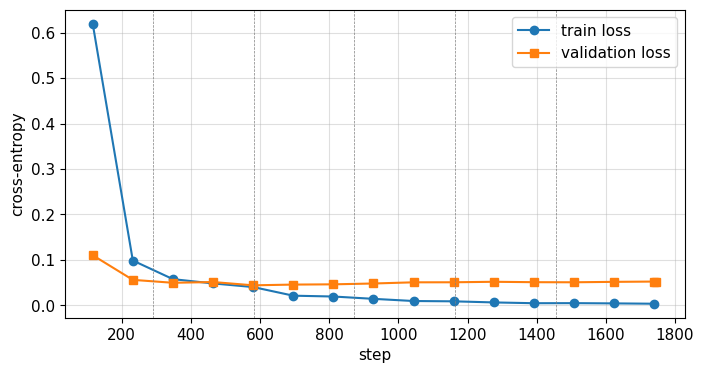

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')
steps_per_epoch = math.ceil(len(tokenized['train']) / BATCH_SIZE)
print(f'шагов в эпохе {steps_per_epoch}, всего {steps_per_epoch * EPOCHS}')
print('eval loss:', [(s, round(l, 4)) for s, l in eval_curve])
best_step, best_loss = min(eval_curve, key=lambda x: x[1])
print(f'минимум validation loss {best_loss:.4f} на шаге {best_step} (эпоха {best_step / steps_per_epoch:.1f}), в конце {eval_curve[-1][1]:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
for e in range(1, EPOCHS):
    plt.axvline(e * steps_per_epoch, color='gray', lw=0.5, ls='--')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Для маленькой модели (hidden 312, 3 слоя) нужен learning rate больше, чем у base-моделей: я взял 3e-4 вместо 2e-5 - 5e-5. Batch 32 легко помещается в память T4 и дает 291 шаг на эпоху. Warmup 10% с линейным затуханием и weight decay 0.01 - стандартные настройки для дообучения BERT, fp16 на T4 ускоряет обучение. Эпох 6, чтобы по кривым было видно, когда модель насыщается.

На кривых train loss падает с 0.62 до примерно 0.003, а validation loss достигает минимума 0.0438 на шаге 580 (конец 2-й эпохи) и дальше медленно растет до 0.0521. Это легкое переобучение по loss: модель становится слишком уверенной на train. F1 на validation при этом остается высоким (0.932), поэтому больше эпох точно не нужно, хватило бы 2-3 эпох или ранней остановки по validation loss. Обучение заняло 64.5 с на Tesla T4 в Google Colab: 9 301 предложение, 6 эпох, 1 746 шагов.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = fp = fn = 0
    for g_seq, p_seq in zip(gold, pred):
        for g, p in zip(g_seq, p_seq):
            if p != 'O' and p == g:
                tp += 1
                continue
            fp += p != 'O'
            fn += g != 'O'
    if tp == 0:
        return 0.0
    precision, recall = tp / (tp + fp), tp / (tp + fn)
    return 2 * precision * recall / (precision + recall)

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)

split_scores = {}
for split, gold_s, pred_s in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'=== {split}')
    print(classification_report(gold_s, pred_s, digits=4, zero_division=0))
    split_scores[split] = dict(entity_scores(gold_s, pred_s), token_f1=token_f1(gold_s, pred_s))
    print({k: round(v, 4) for k, v in split_scores[split].items()})

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(split_scores['test'])
final['per_type'] = {t: {k: report[t][k] for k in ['precision', 'recall', 'f1-score', 'support']} for t in ENTITY_TYPES}
final['validation'] = split_scores['validation']


def word_types(tags_list):
    return [t[2:] if t != 'O' else 'O' for tags in tags_list for t in tags]


order = ['O'] + ENTITY_TYPES
conf = collections.Counter(zip(word_types(test_gold), word_types(test_pred)))
print('\nпутаница типов по словам на test (строка - истина, столбец - предсказание):')
print(f'{"":<6}' + ''.join(f'{t:>8}' for t in order))
for gt in order:
    print(f'{gt:<6}' + ''.join(f'{conf[(gt, pt)]:>8}' for pt in order))
for t in ENTITY_TYPES:
    tag_t = [[x if x[2:] == t else 'O' for x in tags] for tags in test_gold]
    pred_t = [[x if x[2:] == t else 'O' for x in tags] for tags in test_pred]
    print(f'{t}: token F1 {token_f1(tag_t, pred_t):.4f}, entity F1 {report[t]["f1-score"]:.4f}')

=== validation
              precision    recall  f1-score   support

         LOC     0.9536    0.9495    0.9515      1168
         ORG     0.8363    0.8983    0.8662      1308
         PER     0.9602    0.9860    0.9729      1641

   micro avg     0.9175    0.9478    0.9324      4117
   macro avg     0.9167    0.9446    0.9302      4117
weighted avg     0.9190    0.9478    0.9330      4117

{'f1_micro': np.float64(0.9324), 'f1_macro': np.float64(0.9302), 'precision': np.float64(0.9175), 'recall': np.float64(0.9478), 'token_f1': 0.9538}
=== test
              precision    recall  f1-score   support

         LOC     0.9473    0.9643    0.9557      1175
         ORG     0.8504    0.8869    0.8683      1256
         PER     0.9600    0.9777    0.9688      1570

   micro avg     0.9213    0.9453    0.9331      4001
   macro avg     0.9192    0.9430    0.9309      4001
weighted avg     0.9219    0.9453    0.9334      4001

{'f1_micro': np.float64(0.9331), 'f1_macro': np.float64(0.9309), '

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего распознается ORG: F1 0.868 на test (P 0.850, R 0.887) против 0.969 у PER и 0.956 у LOC. Организации самые разнообразные (аббревиатуры, названия в кавычках, длинные официальные названия), у них самые длинные спаны (в среднем 2 слова, до 18, однословных только 53.8%), их легко спутать с LOC (Россия как страна и как государство). По матрице путаницы 161 слово `O` предсказано как ORG и 116 слов ORG пропущено, это больше, чем у остальных типов вместе.

Micro (0.933) и macro (0.931) F1 почти не отличаются, потому что классы сбалансированы: macro чуть ниже из-за того, что всем типам дается одинаковый вес, и слабый ORG тянет среднее вниз сильнее.

Токенный F1 выше, чем F1 по сущностям: 0.956 против 0.933 на test. В токенном F1 спан с неверной границей все равно приносит баллы за правильно размеченные слова, а по сущностям он целиком считается ошибкой. Разрыв больше всего у ORG (0.915 против 0.868), где больше всего ошибок границ длинных спанов, и меньше всего у PER (0.983 против 0.969). Пользователю NER нужна сущность целиком, поэтому F1 по сущностям ближе к реальному качеству.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(a, b):
        return min(a[1], b[1]) - max(a[0], b[0])

    pred_set = set(pred_spans)
    result = []
    for g in gold_spans:
        if g in pred_set:
            result.append(('correct', g, g))
            continue
        crossing = [p for p in pred_spans if overlap(g, p) > 0]
        same_type = [p for p in crossing if p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, max(same_type, key=lambda p: overlap(g, p))))
        elif crossing:
            result.append(('type', g, max(crossing, key=lambda p: overlap(g, p))))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) > 0 for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

error_records = []
for i, (g_tags, p_tags) in enumerate(zip(val_gold, val_pred)):
    for cat, g, p in categorize_errors(bio_to_spans(g_tags), bio_to_spans(p_tags)):
        error_records.append((i, cat, g, p))
errors = {c: sum(r[1] == c for r in error_records) for c in ERROR_CATEGORIES}
n_errors = sum(v for c, v in errors.items() if c != 'correct')
error_share = {c: errors[c] / max(n_errors, 1) for c in ERROR_CATEGORIES if c != 'correct'}
print(f'истинных спанов {sum(errors[c] for c in ERROR_CATEGORIES if c != "spurious")}, ошибок всего {n_errors}')
for c in ERROR_CATEGORIES:
    share = f'{error_share[c]:.1%} ошибок' if c != 'correct' else ''
    print(f'{c:<9}{errors[c]:>6}  {share}')

print('\nпо типам (для spurious - тип предсказания):')
by_type = collections.Counter((r[1], (r[2] or r[3])[2]) for r in error_records)
print(f'{"":<9}' + ''.join(f'{t:>7}' for t in ENTITY_TYPES))
for c in ERROR_CATEGORIES:
    print(f'{c:<9}' + ''.join(f'{by_type[(c, t)]:>7}' for t in ENTITY_TYPES))
print('ошибки типа (истина -> предсказание):', collections.Counter((g[2], p[2]) for _, c, g, p in error_records if c == 'type').most_common())
bnd = collections.Counter('шире' if p[0] <= g[0] and p[1] >= g[1] else 'уже' if p[0] >= g[0] and p[1] <= g[1] else 'сдвиг'
                          for _, c, g, p in error_records if c == 'boundary')
print('ошибки границы: предсказанный спан', dict(bnd))
miss_len = [g[1] - g[0] for _, c, g, _ in error_records if c == 'missed']
print(f'средняя длина пропущенных спанов {np.mean(miss_len) if miss_len else 0:.2f} слов, всех истинных '
      f'{np.mean([g[1] - g[0] for _, c, g, _ in error_records if g is not None]):.2f}')


def show_span(words, span):
    return 'None' if span is None else f'[{" ".join(words[span[0]:span[1]])}]/{span[2]}'


def show_sentence(words, span, width=10):
    lo, hi = max(0, span[0] - width), min(len(words), span[1] + width)
    return ('... ' if lo else '') + ' '.join(words[lo:hi]) + (' ...' if hi < len(words) else '')


rng_show = random.Random(SEED)
for c in ERROR_CATEGORIES[1:]:
    recs = [r for r in error_records if r[1] == c]
    print(f'\n--- {c}: {len(recs)}')
    for i, _, g, p in rng_show.sample(recs, min(4, len(recs))):
        words = val_tokens[i]
        print(f'  #{i}: {show_sentence(words, g or p)}')
        print(f'      gold {show_span(words, g)}  pred {show_span(words, p)}')

истинных спанов 4117, ошибок всего 342
correct    3902  
boundary    148  43.3% ошибок
type         44  12.9% ошибок
missed       23  6.7% ошибок
spurious    127  37.1% ошибок

по типам (для spurious - тип предсказания):
             LOC    ORG    PER
correct     1109   1175   1618
boundary      18    112     18
type          31     10      3
missed        10     11      2
spurious      23     90     14
ошибки типа (истина -> предсказание): [(('LOC', 'PER'), 19), (('LOC', 'ORG'), 12), (('ORG', 'PER'), 5), (('ORG', 'LOC'), 5), (('PER', 'ORG'), 2), (('PER', 'LOC'), 1)]
ошибки границы: предсказанный спан {'уже': 90, 'шире': 58}
средняя длина пропущенных спанов 1.70 слов, всех истинных 1.77

--- boundary: 148
  #1309: Александр Галдин родился в 1948 году в селе Самарино Ряжского района Рязанской области .
      gold [Ряжского района]/LOC  pred [Самарино Ряжского района]/LOC
  #1595: Спикер Сената Крин Антонеску из СЛС был назначен временно исполняющим обязанности Президента .
      gold [К

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation 342 ошибки на 4 117 истинных спанов. Самая частая категория - ошибка границы (148, 43.3% ошибок), дальше лишние спаны (127, 37.1%), ошибки типа (44, 12.9%) и пропуски (23, 6.7%). Почти все проблемы - с ORG: 112 из 148 ошибок границы и 90 из 127 лишних спанов.

Что общего у примеров: в ошибках границы предсказанный спан чаще уже истинного (90 против 58), и особенно часто это кавычки в названиях (`ОК " Русал "` -> `ОК "`) и составные топонимы (`Самарино Ряжского района`). Ошибки типа - в основном LOC -> PER (19 из 44): редкие топонимы и прилагательные-названия районов (Доху, Жанаозене, Кирсановский) похожи на фамилии. Лишние спаны - заглавные нарицательные слова и аббревиатуры (`План`, `Конституционную декларацию`, `ВИЭ`) и одиночные кавычки. Пропуски - короткие сущности внутри других (`РФ` в `МВД РФ`) и названия СМИ.

Часть ошибок на самом деле ошибки разметки: `FM - радиостанцию` размечено как ORG, в `Самарино Ряжского района` село не вошло в LOC, хотя модель его включила, кавычки то входят в название, то нет, `МВД РФ` где-то размечено одним ORG, а где-то как ORG + LOC.

Чтобы уменьшить ошибки границы, я бы сначала нормализовал разметку кавычек (всегда включать их в ORG или всегда исключать), добавил постобработку, которая расширяет спан ORG до парной кавычки, и попробовал CRF-слой поверх энкодера. Самый простой путь - модель побольше: в 6.2 у rubert-base F1 по ORG 0.942 против 0.868.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

                      f1_micro        f1_macro       precision          recall        token_f1       train_sectrainable_params final_eval_loss
baseline_run            0.9324          0.9302          0.9175          0.9478          0.9538         64.4956      29,098,303          0.0521
ablated_run             0.6973          0.6919          0.6595          0.7396          0.7662         32.5736           2,191          0.1644
              precision    recall  f1-score   support

         LOC     0.7720    0.8031    0.7872      1168
         ORG     0.4771    0.5260    0.5004      1308
         PER     0.7240    0.8647    0.7881      1641

   micro avg     0.6595    0.7396    0.6973      4117
   macro avg     0.6577    0.7313    0.6919      4117
weighted avg     0.6592    0.7396    0.6964      4117



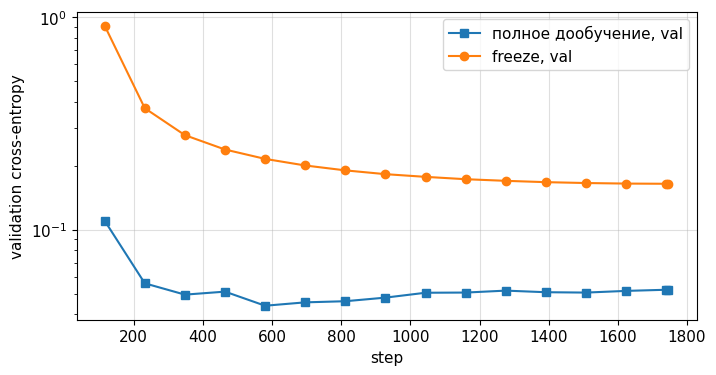

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
ablation = {}


def trainable_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


main_trainable = sum(p.numel() for p in model.parameters())
set_seed(SEED)
abl_model = make_model()
if ABLATION == 'freeze':
    abl_train, abl_eval, abl_kwargs = tokenized['train'], tokenized['validation'], dict(freeze_encoder=True)
else:
    abl_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                        fn_kwargs=dict(label_all_subwords=True))
    abl_train, abl_eval, abl_kwargs = abl_data['train'], abl_data['validation'], {}
abl_history, abl_seconds = train_ner(abl_model, abl_train, abl_eval, out_dir='runs/ablation', **abl_kwargs)
RUN_TIMES['train_ablation_sec'] = abl_seconds
abl_trainable = trainable_params(abl_model)
abl_pred = predict_word_tags(abl_model, val_tokens)

ablation = dict(
    setting=ABLATION, split='validation',
    baseline_run=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
                      train_sec=train_seconds, trainable_params=main_trainable,
                      final_eval_loss=[h['eval_loss'] for h in history if 'eval_loss' in h][-1]),
    ablated_run=dict(entity_scores(val_gold, abl_pred), token_f1=token_f1(val_gold, abl_pred),
                     train_sec=abl_seconds, trainable_params=abl_trainable,
                     final_eval_loss=[h['eval_loss'] for h in abl_history if 'eval_loss' in h][-1]))
for p in abl_model.parameters():
    p.requires_grad = True

print(f'{"":<14}' + ''.join(f'{k:>16}' for k in ablation['baseline_run']))
for name in ['baseline_run', 'ablated_run']:
    print(f'{name:<14}' + ''.join(f'{v:>16.4f}' if isinstance(v, float) else f'{v:>16,}' for v in ablation[name].values()))
print(classification_report(val_gold, abl_pred, digits=4, zero_division=0))

plt.figure(figsize=(8, 4))
plt.plot(*zip(*[(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]), 's-', label='полное дообучение, val')
plt.plot(*zip(*[(h['step'], h['eval_loss']) for h in abl_history if 'eval_loss' in h]), 'o-', label=f'{ABLATION}, val')
plt.xlabel('step')
plt.ylabel('validation cross-entropy')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()
del abl_model

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** С замороженным энкодером F1 на validation упал с 0.932 до 0.697 (-0.235), токенный F1 - с 0.954 до 0.766, сильнее всего пострадал ORG (0.500). Обучаемых параметров 2 191 вместо 29.1M, обучение ускорилось примерно вдвое (32.6 с против 64.5 с), а не в тысячи раз, потому что прямой проход через весь энкодер все равно нужен на каждом шаге.

Объяснение: rubert-tiny2 предобучался под эмбеддинги предложений и MLM, а не под разметку токенов, поэтому его признаки линейно плохо разделяют BIO-теги, особенно `B-` и `I-` и границы длинных ORG. Validation loss у замороженной модели в конце 0.164 против 0.052, и кривая еще медленно снижается: часть отставания связана с тем, что LR 3e-4 подбирался для полного дообучения, а для одной головы он маленький.

Чтобы вывод был надежнее, я бы подобрал LR для головы отдельно (1e-3 - 1e-2) и дал больше эпох, повторил оба варианта на 3-5 сидах и оценил разброс, а также попробовал промежуточный вариант с размороженным последним слоем.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение rubert-tiny2 сработало хорошо: F1 по сущностям на test 0.933 (macro 0.931, токенный 0.956) против 0.561 у словарного бейзлайна и 0.038 у случайной головы, а обучение заняло всего 64.5 с на T4. Лучше всего распознаются PER (0.969) и LOC (0.956), хуже всего ORG (0.868), и больше половины ошибок - границы и лишние спаны у организаций. Заморозка энкодера не работает: F1 падает до 0.697, то есть признаки нужно дообучать, одной линейной головы мало. Главные ограничения - маленькая модель (rubert-base в 6.2 дает 0.975, но в 6 раз больше и в 3.6 раза дольше обучается), шум разметки (кавычки, `I-` без `B-`, спорные спаны вроде `FM - радиостанцию`) и сильная зависимость от регистра (6.3: в нижнем регистре F1 падает до 0.13). Validation loss минимален уже после 2 эпох, так что 6 эпох были лишними. Дальше я бы почистил разметку кавычек в ORG, добавил аугментацию регистром и опечатками, порог уверенности 0.9 (6.5, +0.6 пункта на test), а если важнее качество, чем скорость, взял бы rubert-base.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "split": "validation", "baseline_run": {"f1_micro": 0.9323775388291518, "f1_macro": 0.9302210664658105, "precision": 0.9174700211615331, "recall": 0.9477775078940976, "token_f1": 0.9537935748462064, "train_sec": 64.49564719, "trainable_params": 29098303, "final_eval_loss": 0.05209653452038765}, "ablated_run": {"
final F1 micro 0.9331


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не выполнялся.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    OTHER_ID = 'DeepPavlov/rubert-base-cased'
    OTHER_REVISION = '4036cab694767a299f2b9e6492909664d9414229'
    OTHER_LR = 3e-5
    other_info = HfApi().model_info(OTHER_ID, revision=OTHER_REVISION, files_metadata=True)
    other_card = other_info.card_data.to_dict() if other_info.card_data else {}
    print(f'{OTHER_ID} revision {OTHER_REVISION}, license {other_card.get("license")}')
    other_tok = AutoTokenizer.from_pretrained(OTHER_ID, revision=OTHER_REVISION)
    assert other_tok.is_fast
    other_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=other_tok))
    print('сабвордов на предложение train:',
          f'{MODEL_ID} {np.mean([len(x) for x in tokenized["train"]["input_ids"]]):.1f},',
          f'{OTHER_ID} {np.mean([len(x) for x in other_tokenized["train"]["input_ids"]]):.1f}')

    set_seed(SEED)
    other_model = make_model(OTHER_ID, OTHER_REVISION)
    other_history, other_seconds = train_ner(other_model, other_tokenized['train'], other_tokenized['validation'],
                                             lr=OTHER_LR, tok=other_tok, out_dir='runs/other')
    RUN_TIMES['train_other_sec'] = other_seconds

    def timed_predict(m, tokens, tok):
        predict_word_tags(m, tokens[:64], tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        pred = predict_word_tags(m, tokens, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return pred, time.perf_counter() - start

    compare = {}
    for name, m, tok, sec in [(MODEL_ID, model, tokenizer, train_seconds), (OTHER_ID, other_model, other_tok, other_seconds)]:
        if device.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()
        v_pred, v_sec = timed_predict(m, val_tokens, tok)
        t_pred = predict_word_tags(m, test_tokens, tok=tok)
        compare[name] = dict(
            params=sum(p.numel() for p in m.parameters()),
            size_mb=sum(p.numel() * p.element_size() for p in m.parameters()) / 2**20,
            train_sec=sec, val_infer_sec=v_sec,
            val_f1=f1_score(val_gold, v_pred), test_f1=f1_score(test_gold, t_pred),
            test_f1_macro=f1_score(test_gold, t_pred, average='macro'),
            peak_infer_mem_mb=torch.cuda.max_memory_allocated() / 2**20 if device.type == 'cuda' else None)
        compare[name]['per_type_test_f1'] = {t: classification_report(test_gold, t_pred, output_dict=True, zero_division=0)[t]['f1-score']
                                             for t in ENTITY_TYPES}
    other_eval = [(h['step'], h['eval_loss']) for h in other_history if 'eval_loss' in h]
    print('eval loss', OTHER_ID, [(s, round(l, 4)) for s, l in other_eval])
    for name, row in compare.items():
        print(name)
        for k, v in row.items():
            print(f'    {k:<18}', {kk: round(vv, 4) for kk, vv in v.items()} if isinstance(v, dict) else
                  (f'{v:,.4f}' if isinstance(v, float) else v))
    BONUS = globals().get('BONUS', {})
    BONUS['6.2'] = dict(other_model=OTHER_ID, other_revision=OTHER_REVISION, other_lr=OTHER_LR, compare=compare)
    other_model = other_model.cpu()
    del other_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()

DeepPavlov/rubert-base-cased revision 4036cab694767a299f2b9e6492909664d9414229, license None


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

eval loss DeepPavlov/rubert-base-cased [(116, 0.0575), (232, 0.0264), (348, 0.0264), (464, 0.0218), (580, 0.0264), (696, 0.0234), (812, 0.021), (928, 0.0228), (1044, 0.0213), (1160, 0.0278), (1276, 0.0248), (1392, 0.0253), (1508, 0.026), (1624, 0.0272), (1740, 0.0269), (1746, 0.0269)]
cointegrated/rubert-tiny2
    params             29098303
    size_mb            111.0012
    train_sec          64.4956
    val_infer_sec      1.1179
    val_f1             0.9324
    test_f1            0.9331
    test_f1_macro      0.9309
    peak_infer_mem_mb  2,358.4858
    per_type_test_f1   {'LOC': np.float64(0.9557), 'ORG': np.float64(0.8683), 'PER': np.float64(0.9688)}
DeepPavlov/rubert-base-cased
    params             177268231
    size_mb            676.2246
    train_sec          234.4433
    val_infer_sec      2.3011
    val_f1             0.9741
    test_f1            0.9747
    test_f1_macro      0.9730
    peak_infer_mem_mb  1,162.6807
    per_type_test_f1   {'LOC': np.float64(0.9797), 'OR

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** rubert-base-cased заметно лучше: F1 на test 0.975 против 0.933 (+4.2 пункта), на validation 0.974 против 0.932. Больше всего выигрыш на ORG (0.942 против 0.868), PER почти идеален (0.997). Цена: 177.3M параметров против 29.1M (в 6.1 раза больше), 676 МБ весов в fp32 против 111 МБ, обучение 234 с против 64.5 с (в 3.6 раза дольше), инференс на validation 2.30 с против 1.12 с (в 2.1 раза дольше). Пиковая память в моем замере некорректна (у tiny получилось 2 358 МБ, у base 1 163 МБ): `reset_peak_memory_stats` не освобождает тензоры, оставшиеся на GPU после обучения, поэтому эти числа нельзя сравнивать.

Честность сравнения: одинаковые сплиты и подмножества, `MAX_LENGTH = 128`, 6 эпох, batch 32, warmup и weight decay, один seed, одинаковая оценка по словам через `predict_word_tags` и seqeval. Отличается только LR (3e-4 для tiny и стандартный 3e-5 для base), потому что оптимальный LR зависит от размера модели. Каждая модель обучалась один раз, так что разница в доли пункта была бы незначимой, но 4 пункта - устойчивый эффект.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

lower: пример -> президент сша барак обама в пятницу , 19 июня , назвал кандидатов на посты
upper: пример -> ПРЕЗИДЕНТ США БАРАК ОБАМА В ПЯТНИЦУ , 19 ИЮНЯ , НАЗВАЛ КАНДИДАТОВ НА ПОСТЫ
typos_30%: пример -> Президент США Барак Обама в пятницу , 19 июня , наазвал кандидатов на посты
translit: пример -> Prezident SShA Barak Obama v pyatnitsu , 19 iyunya , nazval kandidatov na posty
no_punct: пример -> Президент США Барак Обама в пятницу 19 июня назвал кандидатов на посты послов в

                     f1_micro         precision            recall subwords_per_word            f1_LOC            f1_ORG            f1_PER
clean                  0.9324            0.9175            0.9478            1.1435            0.9515            0.8662            0.9729
lower                  0.1316            0.4295            0.0777            1.2420            0.0490            0.1094            0.1958
upper                  0.0792            0.0505            0.1831            3.4743            0.1238   

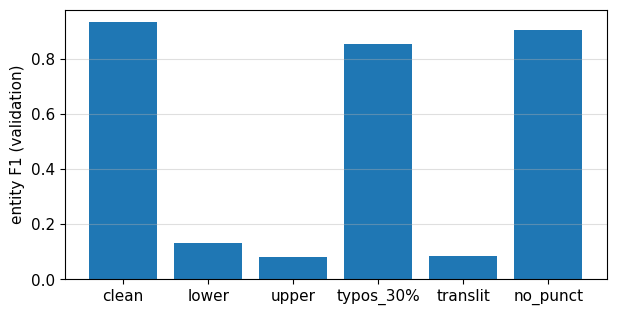

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't',
                         'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))

    def translit_word(w):
        out = []
        for ch in w:
            low = ch.lower()
            if low in TRANSLIT:
                rep = TRANSLIT[low]
                out.append(rep.capitalize() if ch != low else rep)
            else:
                out.append(ch)
        return ''.join(out) or w

    def typo_word(w, rng, p=0.3):
        if len(w) < 4 or not w.isalpha() or rng.random() > p:
            return w
        i = rng.randrange(1, len(w) - 1)
        op = rng.choice(['swap', 'drop', 'repeat', 'replace'])
        if op == 'swap':
            return w[:i] + w[i + 1] + w[i] + w[i + 2:]
        if op == 'drop':
            return w[:i] + w[i + 1:]
        if op == 'repeat':
            return w[:i] + w[i] + w[i:]
        alphabet = 'абвгдежзийклмнопрстуфхцчшщыэюя' if re.search('[а-яё]', w.lower()) else 'abcdefghijklmnopqrstuvwxyz'
        return w[:i] + rng.choice(alphabet) + w[i + 1:]

    rng_shift = random.Random(SEED)
    corruptions = {
        'clean': lambda ws: ws,
        'lower': lambda ws: [w.lower() for w in ws],
        'upper': lambda ws: [w.upper() for w in ws],
        'typos_30%': lambda ws: [typo_word(w, rng_shift) for w in ws],
        'translit': lambda ws: [translit_word(w) for w in ws],
        'no_punct': lambda ws: [w if re.search(r'\w', w) else '' for w in ws],
    }
    shift = {}
    for name, fn in corruptions.items():
        corrupted = [fn(list(ws)) for ws in val_tokens]
        if name == 'no_punct':
            keep = [[i for i, w in enumerate(ws) if w] for ws in corrupted]
            corrupted = [[ws[i] for i in k] for ws, k in zip(corrupted, keep)]
            gold_c = [[gs[i] for i in k] for gs, k in zip(val_gold, keep)]
        else:
            gold_c = val_gold
        pred_c = predict_word_tags(model, corrupted)
        rep_c = classification_report(gold_c, pred_c, output_dict=True, zero_division=0)
        fert = np.mean([len(tokenizer.tokenize(w)) for ws in corrupted[:300] for w in ws if w])
        shift[name] = dict(f1_micro=f1_score(gold_c, pred_c), precision=precision_score(gold_c, pred_c),
                           recall=recall_score(gold_c, pred_c), subwords_per_word=fert,
                           **{f'f1_{t}': rep_c[t]['f1-score'] for t in ENTITY_TYPES})
        if name != 'clean':
            print(f'{name}: пример ->', ' '.join(corrupted[1][:14]))
    print(f'\n{"":<11}' + ''.join(f'{k:>18}' for k in shift['clean']))
    for name, row in shift.items():
        print(f'{name:<11}' + ''.join(f'{v:>18.4f}' for v in row.values()))
    plt.figure(figsize=(7, 3.5))
    plt.bar(list(shift), [r['f1_micro'] for r in shift.values()])
    plt.ylabel('entity F1 (validation)')
    plt.grid(True, axis='y', alpha=0.4)
    plt.show()
    BONUS = globals().get('BONUS', {})
    BONUS['6.3'] = shift

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего F1 роняет верхний регистр: 0.079 против 0.932 на чистых данных, дальше транслит (0.082) и нижний регистр (0.132). Опечатки в 30% слов снижают F1 до 0.854, удаление пунктуации - до 0.906.

Модель cased, и заглавная буква - главный признак сущности в русском тексте. В нижнем регистре этот признак пропадает: модель почти перестает находить сущности (recall 0.078 при precision 0.43). В верхнем регистре каждое слово выглядит как аббревиатура вроде МВД или ГУВД, а токенизатор режет слова на мелкие куски (3.47 сабворда на слово против 1.14), поэтому модель находит лишние сущности везде (precision 0.05). Транслит переводит текст в латиницу, где русские сабворды словаря не работают (2.46 сабворда на слово), немного держится только PER (0.151), потому что известные имена вроде Obama есть и в латинице. При опечатках заглавные буквы и контекст сохраняются, поэтому падение умеренное. Без пунктуации теряются кавычки и запятые, которые помогают определять границы ORG и перечислений.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import subprocess
    import sys
    import types
    import warnings
    warnings.simplefilter('ignore')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'onnxscript'], check=False)
    import onnxruntime as ort

    cpu = torch.device('cpu')
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    model_cpu = copy.deepcopy(model).cpu().eval()

    class LogitsOnly(torch.nn.Module):
        def __init__(self, m):
            super().__init__()
            self.m = m

        def forward(self, input_ids, attention_mask):
            return self.m(input_ids=input_ids, attention_mask=attention_mask).logits

    sample = tokenizer(val_tokens[:2], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    onnx_path = ARTIFACTS.parent / 'runs' / 'ner.onnx'
    onnx_path.parent.mkdir(exist_ok=True)
    export_args = (sample['input_ids'], sample['attention_mask'])
    try:
        torch.onnx.export(LogitsOnly(model_cpu).eval(), export_args, str(onnx_path), input_names=['input_ids', 'attention_mask'],
                          output_names=['logits'], opset_version=17, dynamo=False,
                          dynamic_axes={'input_ids': {0: 'batch', 1: 'seq'}, 'attention_mask': {0: 'batch', 1: 'seq'}, 'logits': {0: 'batch', 1: 'seq'}})
    except Exception as exc:
        print('legacy export failed, dynamo export:', type(exc).__name__)
        batch_dim, seq_dim = torch.export.Dim('batch'), torch.export.Dim('seq', max=MAX_LENGTH)
        torch.onnx.export(LogitsOnly(model_cpu).eval(), export_args, str(onnx_path), input_names=['input_ids', 'attention_mask'],
                          output_names=['logits'], dynamo=True,
                          dynamic_shapes={'input_ids': {0: batch_dim, 1: seq_dim}, 'attention_mask': {0: batch_dim, 1: seq_dim}})
    model_cpu.eval()
    session = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])

    class OnnxTokenClassifier:
        def __init__(self, sess, config):
            self.sess, self.config = sess, config

        def eval(self):
            return self

        def to(self, dev):
            return self

        def __call__(self, input_ids, attention_mask, **kwargs):
            logits = self.sess.run(['logits'], {'input_ids': input_ids.cpu().numpy().astype(np.int64),
                                                'attention_mask': attention_mask.cpu().numpy().astype(np.int64)})[0]
            return types.SimpleNamespace(logits=torch.from_numpy(logits))

    onnx_model = OnnxTokenClassifier(session, model.config)
    quant_model = None
    try:
        quant_model = torch.ao.quantization.quantize_dynamic(copy.deepcopy(model_cpu), {torch.nn.Linear}, dtype=torch.qint8).eval()
    except Exception as exc:
        print('dynamic quantization недоступна:', exc)

    bench = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    print('батч для замера:', tuple(bench['input_ids'].shape))

    def latency(fn, n_warm=3, n_runs=20, sync=False):
        for _ in range(n_warm):
            fn()
        times = []
        for _ in range(n_runs):
            if sync:
                torch.cuda.synchronize()
            start = time.perf_counter()
            fn()
            if sync:
                torch.cuda.synchronize()
            times.append(time.perf_counter() - start)
        return 1000 * float(np.mean(times)), 1000 * float(np.std(times))

    variants = {'pytorch_fp32_cpu': (model_cpu, cpu), 'onnxruntime_cpu': (onnx_model, cpu)}
    if quant_model is not None:
        variants['pytorch_int8_dynamic_cpu'] = (quant_model, cpu)
    export = {}
    ref_logits = model_cpu(input_ids=bench['input_ids'], attention_mask=bench['attention_mask']).logits.detach()
    for name, (m, dev) in variants.items():
        with torch.inference_mode():
            mean_ms, std_ms = latency(lambda: m(input_ids=bench['input_ids'], attention_mask=bench['attention_mask']))
            logits = m(input_ids=bench['input_ids'], attention_mask=bench['attention_mask']).logits
        pred_v = predict_word_tags(m, val_tokens, dev=dev)
        export[name] = dict(latency_ms=mean_ms, latency_std_ms=std_ms, val_f1=f1_score(val_gold, pred_v),
                            max_abs_logit_diff=float((logits.float() - ref_logits).abs().max()),
                            tag_agreement=float(np.mean([a == b for x, y in zip(pred_v, val_pred) for a, b in zip(x, y)])))
    if device.type == 'cuda':
        gpu_model = model.to(device).eval()
        gb = {k: v.to(device) for k, v in bench.items() if k in ('input_ids', 'attention_mask')}
        with torch.inference_mode():
            export['pytorch_fp32_gpu'] = dict(zip(['latency_ms', 'latency_std_ms'], latency(lambda: gpu_model(**gb), sync=True)))
            with torch.autocast('cuda', dtype=torch.float16):
                export['pytorch_fp16_autocast_gpu'] = dict(zip(['latency_ms', 'latency_std_ms'], latency(lambda: gpu_model(**gb), sync=True)))
    onnx_mb = onnx_path.stat().st_size / 2**20
    torch.save(model_cpu.state_dict(), ARTIFACTS.parent / 'runs' / 'fp32.pt')
    sizes = {'pytorch_fp32_cpu': (ARTIFACTS.parent / 'runs' / 'fp32.pt').stat().st_size / 2**20, 'onnxruntime_cpu': onnx_mb}
    if quant_model is not None:
        torch.save(quant_model.state_dict(), ARTIFACTS.parent / 'runs' / 'int8.pt')
        sizes['pytorch_int8_dynamic_cpu'] = (ARTIFACTS.parent / 'runs' / 'int8.pt').stat().st_size / 2**20
    for name, mb in sizes.items():
        export[name]['file_mb'] = mb
    base_ms = export['pytorch_fp32_cpu']['latency_ms']
    for name, row in export.items():
        row['speedup_vs_fp32_cpu'] = base_ms / row['latency_ms']
        print(f'{name:<26}', {k: round(v, 4) for k, v in row.items()})
    linear_params = sum(m.weight.numel() for m in model_cpu.modules() if isinstance(m, torch.nn.Linear))
    print(f'параметров в Linear (их квантует dynamic int8): {linear_params:,} из {sum(p.numel() for p in model_cpu.parameters()):,}')
    print(f'cpu threads: {torch.get_num_threads()}')
    BONUS = globals().get('BONUS', {})
    BONUS['6.4'] = export
    model.to(device)

батч для замера: (32, 48)
pytorch_fp32_cpu           {'latency_ms': 87.5673, 'latency_std_ms': 9.8898, 'val_f1': np.float64(0.9324), 'max_abs_logit_diff': 0.0, 'tag_agreement': 1.0, 'file_mb': 111.0197, 'speedup_vs_fp32_cpu': 1.0}
onnxruntime_cpu            {'latency_ms': 101.24, 'latency_std_ms': 5.1432, 'val_f1': np.float64(0.9324), 'max_abs_logit_diff': 0.0, 'tag_agreement': 1.0, 'file_mb': 111.095, 'speedup_vs_fp32_cpu': 0.8649}
pytorch_int8_dynamic_cpu   {'latency_ms': 77.7038, 'latency_std_ms': 8.6974, 'val_f1': np.float64(0.9322), 'max_abs_logit_diff': 2.7333, 'tag_agreement': 0.999, 'file_mb': 104.472, 'speedup_vs_fp32_cpu': 1.1269}
pytorch_fp32_gpu           {'latency_ms': 5.0633, 'latency_std_ms': 0.4202, 'speedup_vs_fp32_cpu': 17.2944}
pytorch_fp16_autocast_gpu  {'latency_ms': 4.6589, 'latency_std_ms': 0.09, 'speedup_vs_fp32_cpu': 18.7956}
параметров в Linear (их квантует dynamic int8): 2,293,512 из 29,098,303
cpu threads: 2


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Замер на CPU в Colab (2 потока), батч 32 x 48 сабвордов, 3 прогрева и среднее по 20 запускам. PyTorch fp32 - 87.6 мс, ONNX Runtime - 101.2 мс (ускорения нет, 0.86x), dynamic int8 квантизация - 77.7 мс (1.13x, но это в пределах разброса около ±9 мс). Для сравнения, на T4 тот же батч занимает 5.06 мс в fp32 и 4.66 мс с fp16 autocast. Метрика не изменилась: у ONNX F1 тот же (0.9324, максимальная разница логитов 3.5e-5), у int8 F1 0.9322 (-0.0002, совпадает 99.9% тегов).

Выигрыш маленький, потому что у rubert-tiny2 92% параметров в таблице эмбеддингов, а это поиск по таблице, а не вычисление: dynamic int8 квантует только Linear-слои (2.29M из 29.1M параметров), поэтому файл уменьшился лишь со 111 до 104 МБ. Вычислений в трех узких слоях (hidden 312) так мало, что основное время уходит на накладные расходы запуска операций, которые квантизация и ONNX не убирают. У base-модели вроде rubert-base-cased основная часть параметров и FLOP сидит в 12 слоях энкодера, там квантизация и ONNX дали бы заметное ускорение.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

проверка: F1 при пороге 0 = 0.9324, seqeval = 0.9324
mean {'best_threshold': 0.9, 'val_f1_at_0': 0.9324, 'val_f1_best': 0.9396, 'val_precision_best': 0.9494, 'val_recall_best': 0.93, 'test_f1_at_0': 0.9331, 'test_f1_at_best': 0.9388}
min {'best_threshold': 0.88, 'val_f1_at_0': 0.9324, 'val_f1_best': 0.9394, 'val_precision_best': 0.9532, 'val_recall_best': 0.9259, 'test_f1_at_0': 0.9331, 'test_f1_at_best': 0.9395}
спанов на validation 4253, со средней уверенностью < 0.9: 5.2%


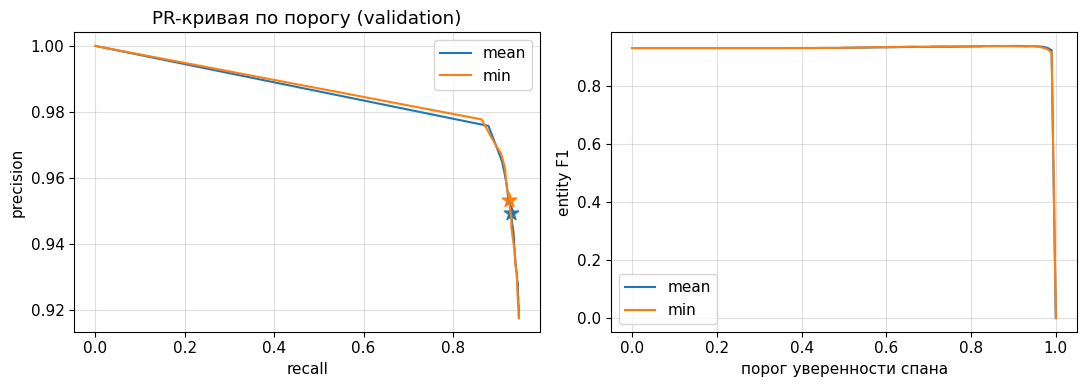

In [34]:
if '6.5' in BONUS_TASKS:
    def span_conf(probs, span, how):
        vals = probs[span[0]:span[1]]
        return float(np.mean(vals)) if how == 'mean' else float(np.min(vals))

    def threshold_curve(gold_tags, pred_tags, pred_probs, how, thresholds):
        gold_sets = [set(bio_to_spans(g)) for g in gold_tags]
        n_gold = sum(len(s) for s in gold_sets)
        scored = [[(s, span_conf(pr, s, how)) for s in bio_to_spans(p)] for p, pr in zip(pred_tags, pred_probs)]
        rows = []
        for thr in thresholds:
            tp = n_pred = 0
            for gs, sc in zip(gold_sets, scored):
                kept = [s for s, c in sc if c >= thr]
                n_pred += len(kept)
                tp += sum(s in gs for s in kept)
            p = tp / n_pred if n_pred else 1.0
            r = tp / n_gold if n_gold else 0.0
            rows.append((thr, p, r, 2 * p * r / (p + r) if p + r else 0.0))
        return np.array(rows)

    thresholds = np.round(np.arange(0, 1.0001, 0.01), 2)
    val_tags_p, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
    test_tags_p, test_probs = predict_word_tags(model, test_tokens, return_probs=True)
    assert val_tags_p == val_pred
    thr_result = {}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for how in ['mean', 'min']:
        curve = threshold_curve(val_gold, val_tags_p, val_probs, how, thresholds)
        best = curve[curve[:, 3].argmax()]
        test_curve = threshold_curve(test_gold, test_tags_p, test_probs, how, [0.0, best[0]])
        thr_result[how] = dict(best_threshold=float(best[0]), val_f1_at_0=float(curve[0, 3]), val_f1_best=float(best[3]),
                               val_precision_best=float(best[1]), val_recall_best=float(best[2]),
                               test_f1_at_0=float(test_curve[0, 3]), test_f1_at_best=float(test_curve[1, 3]))
        axes[0].plot(curve[:, 2], curve[:, 1], label=f'{how}')
        axes[0].scatter([best[2]], [best[1]], marker='*', s=120)
        axes[1].plot(curve[:, 0], curve[:, 3], label=f'{how}')
    print(f'проверка: F1 при пороге 0 = {thr_result["mean"]["val_f1_at_0"]:.4f}, seqeval = {f1_score(val_gold, val_pred):.4f}')
    for how, row in thr_result.items():
        print(how, {k: round(v, 4) for k, v in row.items()})
    span_confs = [span_conf(pr, s, 'mean') for p, pr in zip(val_tags_p, val_probs) for s in bio_to_spans(p)]
    print(f'спанов на validation {len(span_confs)}, со средней уверенностью < 0.9: {np.mean(np.array(span_confs) < 0.9):.1%}')
    axes[0].set_xlabel('recall')
    axes[0].set_ylabel('precision')
    axes[0].set_title('PR-кривая по порогу (validation)')
    axes[1].set_xlabel('порог уверенности спана')
    axes[1].set_ylabel('entity F1')
    for ax in axes:
        ax.legend()
        ax.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.show()
    BONUS = globals().get('BONUS', {})
    BONUS['6.5'] = thr_result

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший порог для средней уверенности - 0.90: F1 на validation растет с 0.9324 до 0.9396 (+0.7 пункта), precision - с 0.917 до 0.949, recall падает с 0.948 до 0.930. Для минимальной уверенности лучший порог 0.88 и F1 0.9394. Проверка на test с порогом, подобранным на validation: 0.9331 -> 0.9388 (mean) и 0.9395 (min), то есть прирост сохраняется (+0.6 пункта).

Минимальная уверенность строже: один неуверенный токен выкидывает весь спан, что полезно для длинных спанов, где сомнение обычно на граничном слове. Средняя сглаживает такие случаи. Здесь разница почти нулевая, потому что спаны в основном короткие и только 5.2% спанов имеют среднюю уверенность ниже 0.9.

Порог может только убрать предсказанные спаны, но не может добавить новые или исправить границы. Поэтому число верных срабатываний не растет, и recall при росте порога может только падать.

### Сохранение результатов бонусов

Метрики бонусов и время всех запусков пишутся в `artifacts/bonus_metrics.json`.

In [35]:
bonus_metrics = dict(bonus_tasks=sorted(BONUS_TASKS), fast_mode=FAST_MODE, run_times=RUN_TIMES, **globals().get('BONUS', {}))
(ARTIFACTS / 'bonus_metrics.json').write_text(json.dumps(json_ready(bonus_metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(sorted(bonus_metrics))

['6.2', '6.3', '6.4', '6.5', 'bonus_tasks', 'fast_mode', 'run_times']
